In [44]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("WA_Fn-UseC_-HR-Employee-Attrition.csv")

In [45]:
print(df.head())

   Age Attrition     BusinessTravel  DailyRate              Department  \
0   41       Yes      Travel_Rarely       1102                   Sales   
1   49        No  Travel_Frequently        279  Research & Development   
2   37       Yes      Travel_Rarely       1373  Research & Development   
3   33        No  Travel_Frequently       1392  Research & Development   
4   27        No      Travel_Rarely        591  Research & Development   

   DistanceFromHome  Education EducationField  EmployeeCount  EmployeeNumber  \
0                 1          2  Life Sciences              1               1   
1                 8          1  Life Sciences              1               2   
2                 2          2          Other              1               4   
3                 3          4  Life Sciences              1               5   
4                 2          1        Medical              1               7   

   ...  RelationshipSatisfaction StandardHours  StockOptionLevel  \
0  ...

In [46]:
print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nMissing values:")
print(df.isnull().sum())

Dataset shape: (1470, 35)

Column names:
['Age', 'Attrition', 'BusinessTravel', 'DailyRate', 'Department', 'DistanceFromHome', 'Education', 'EducationField', 'EmployeeCount', 'EmployeeNumber', 'EnvironmentSatisfaction', 'Gender', 'HourlyRate', 'JobInvolvement', 'JobLevel', 'JobRole', 'JobSatisfaction', 'MaritalStatus', 'MonthlyIncome', 'MonthlyRate', 'NumCompaniesWorked', 'Over18', 'OverTime', 'PercentSalaryHike', 'PerformanceRating', 'RelationshipSatisfaction', 'StandardHours', 'StockOptionLevel', 'TotalWorkingYears', 'TrainingTimesLastYear', 'WorkLifeBalance', 'YearsAtCompany', 'YearsInCurrentRole', 'YearsSinceLastPromotion', 'YearsWithCurrManager']

Data types:
Age                          int64
Attrition                   object
BusinessTravel              object
DailyRate                    int64
Department                  object
DistanceFromHome             int64
Education                    int64
EducationField              object
EmployeeCount                int64
EmployeeNumb

In [47]:
print(df.nunique())

Age                           43
Attrition                      2
BusinessTravel                 3
DailyRate                    886
Department                     3
DistanceFromHome              29
Education                      5
EducationField                 6
EmployeeCount                  1
EmployeeNumber              1470
EnvironmentSatisfaction        4
Gender                         2
HourlyRate                    71
JobInvolvement                 4
JobLevel                       5
JobRole                        9
JobSatisfaction                4
MaritalStatus                  3
MonthlyIncome               1349
MonthlyRate                 1427
NumCompaniesWorked            10
Over18                         1
OverTime                       2
PercentSalaryHike             15
PerformanceRating              2
RelationshipSatisfaction       4
StandardHours                  1
StockOptionLevel               4
TotalWorkingYears             40
TrainingTimesLastYear          7
WorkLifeBa

In [48]:
print("Average monthly income:", df["MonthlyIncome"].mean())

Average monthly income: 6502.931292517007


In [49]:
print(df["Attrition"].value_counts())

print("\nPercentages:")
print(df["Attrition"].value_counts(normalize=True) * 100)

Attrition
No     1233
Yes     237
Name: count, dtype: int64

Percentages:
Attrition
No     83.877551
Yes    16.122449
Name: proportion, dtype: float64


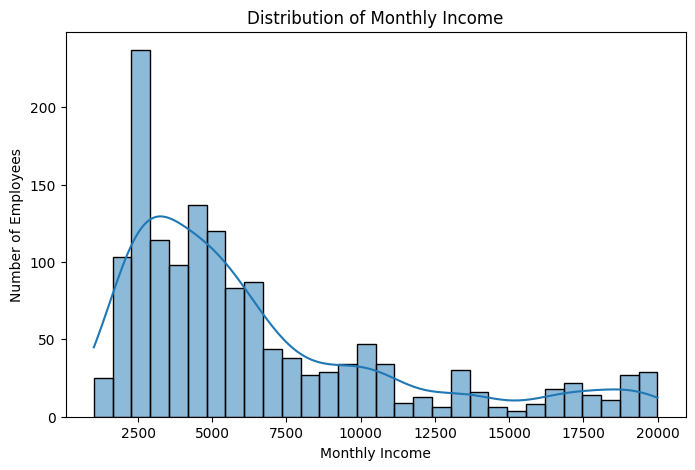

In [50]:
plt.figure(figsize=(8, 5))

sns.histplot(data=df, x="MonthlyIncome", bins=30, kde=True)

plt.title("Distribution of Monthly Income")
plt.xlabel("Monthly Income")
plt.ylabel("Number of Employees")

plt.show()

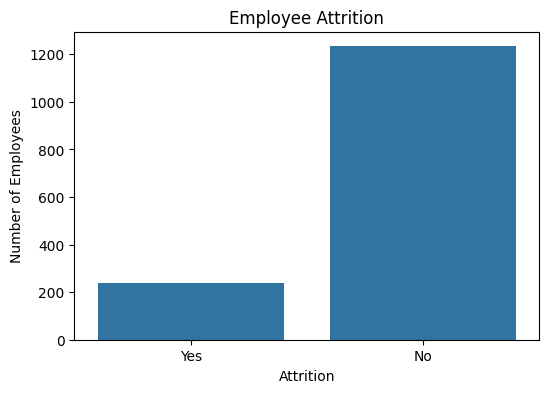

In [51]:
plt.figure(figsize=(6, 4))

sns.countplot(data=df, x="Attrition")

plt.title("Employee Attrition")
plt.xlabel("Attrition")
plt.ylabel("Number of Employees")

plt.show()

### Regression

In [52]:
X = df.drop(
    columns=[
        "MonthlyIncome",
        "EmployeeNumber",
        "EmployeeCount",
        "Over18",
        "StandardHours"
    ]
)

y = df["MonthlyIncome"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (1470, 30)
Target shape: (1470,)


In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=123
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (1176, 30)
Testing data: (294, 30)


In [54]:
numerical_features = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

print("Numerical features:")
print(numerical_features)

print("\nCategorical features:")
print(categorical_features)

Numerical features:
['Age', 'DailyRate', 'DistanceFromHome', 'Education', 'EnvironmentSatisfaction', 'HourlyRate', 'JobInvolvement', 'JobLevel', 'JobSatisfaction', 'MonthlyRate', 'NumCompaniesWorked', 'PercentSalaryHike', 'PerformanceRating', 'RelationshipSatisfaction', 'StockOptionLevel', 'TotalWorkingYears', 'TrainingTimesLastYear', 'WorkLifeBalance', 'YearsAtCompany', 'YearsInCurrentRole', 'YearsSinceLastPromotion', 'YearsWithCurrManager']

Categorical features:
['Attrition', 'BusinessTravel', 'Department', 'EducationField', 'Gender', 'JobRole', 'MaritalStatus', 'OverTime']


In [55]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

numerical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("numerical", numerical_pipeline, numerical_features),
    ("categorical", categorical_pipeline, categorical_features)
])

In [56]:
from sklearn.linear_model import LinearRegression

X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

regression_model = LinearRegression()

regression_model.fit(X_train_processed, y_train)

y_pred_reg = regression_model.predict(X_test_processed)

In [57]:
regression_results = pd.DataFrame({
    "Actual": y_test,
    "Predicted": y_pred_reg
})

print(regression_results.head(10))

      Actual    Predicted
1041    8463  5919.881441
184     4450  5490.244716
1222    1555  2715.522819
67      9724  9112.570060
220     5914  5800.122102
494     2579  2366.747830
430     4230  2513.977745
240     2232  2628.071057
218     8865  9424.325234
49      2269  2291.400081


In [58]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

mae = mean_absolute_error(y_test, y_pred_reg)
rmse = np.sqrt(mean_squared_error(y_test, y_pred_reg))
r2 = r2_score(y_test, y_pred_reg)

print("MAE:", mae)
print("RMSE:", rmse)
print("R²:", r2)

MAE: 893.0470508416333
RMSE: 1168.16157388319
R²: 0.9375622994094824


### Classification

In [60]:
X_cls = df.drop(
    columns=[
        "Attrition",
        "EmployeeNumber",
        "EmployeeCount",
        "Over18",
        "StandardHours"
    ]
)

y_cls = df["Attrition"].map({
    "No": 0,
    "Yes": 1
})

print(X_cls.head())
print(y_cls.value_counts())

   Age     BusinessTravel  DailyRate              Department  \
0   41      Travel_Rarely       1102                   Sales   
1   49  Travel_Frequently        279  Research & Development   
2   37      Travel_Rarely       1373  Research & Development   
3   33  Travel_Frequently       1392  Research & Development   
4   27      Travel_Rarely        591  Research & Development   

   DistanceFromHome  Education EducationField  EnvironmentSatisfaction  \
0                 1          2  Life Sciences                        2   
1                 8          1  Life Sciences                        3   
2                 2          2          Other                        4   
3                 3          4  Life Sciences                        4   
4                 2          1        Medical                        1   

   Gender  HourlyRate  ...  PerformanceRating  RelationshipSatisfaction  \
0  Female          94  ...                  3                         1   
1    Male          6

In [ ]:
X_train_cls, X_test_cls, y_train_cls, y_test_cls = train_test_split(
    X_cls,
    y_cls,
    test_size=0.2,
    random_state=123,
    stratify=y_cls
)

print("Training set:")
print(y_train_cls.value_counts())

print("\nTesting set:")
print(y_test_cls.value_counts())

Training set:
Attrition
0    986
1    190
Name: count, dtype: int64

Testing set:
Attrition
0    247
1     47
Name: count, dtype: int64


In [62]:
numerical_features_cls = X_cls.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features_cls = X_cls.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

numerical_pipeline_cls = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline_cls = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor_cls = ColumnTransformer([
    ("numerical", numerical_pipeline_cls, numerical_features_cls),
    ("categorical", categorical_pipeline_cls, categorical_features_cls)
])

X_train_cls_processed = preprocessor_cls.fit_transform(X_train_cls)
X_test_cls_processed = preprocessor_cls.transform(X_test_cls)

In [ ]:
from sklearn.linear_model import LogisticRegression

classification_model = LogisticRegression(
    max_iter=1000,
    class_weight="balanced",
    random_state=123
)

classification_model.fit(
    X_train_cls_processed,
    y_train_cls
)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,'balanced'
,random_state,42
,solver,'lbfgs'
,max_iter,1000
,multi_class,'deprecated'


In [69]:
y_pred_cls = classification_model.predict(
    X_test_cls_processed
)

y_prob_cls = classification_model.predict_proba(
    X_test_cls_processed
)[:, 1]

In [65]:
classification_results = pd.DataFrame({
    "Actual": y_test_cls,
    "Predicted": y_pred_cls,
    "Probability_of_Leaving": y_prob_cls
})

print(classification_results.head(10))

      Actual  Predicted  Probability_of_Leaving
1061       0          0                0.286610
891        0          0                0.021878
456        0          0                0.407563
922        0          0                0.040382
69         1          1                0.674098
1164       0          1                0.642287
406        0          0                0.080839
1330       0          0                0.150257
1232       0          0                0.020520
1311       0          0                0.237788


In [70]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report
)

accuracy = accuracy_score(y_test_cls, y_pred_cls)

precision = precision_score(
    y_test_cls, y_pred_cls, zero_division=0
)

recall = recall_score(
    y_test_cls, y_pred_cls, zero_division=0
)

f1 = f1_score(
    y_test_cls, y_pred_cls, zero_division=0
)

print("Accuracy:", accuracy)
print("Precision:", precision)
print("Recall:", recall)
print("F1-score:", f1)

Accuracy: 0.7517006802721088
Precision: 0.3488372093023256
Recall: 0.6382978723404256
F1-score: 0.45112781954887216


In [71]:
print(
    classification_report(
        y_test_cls,
        y_pred_cls,
        labels=[0, 1],
        target_names=["Stayed", "Left"],
        zero_division=0
    )
)

              precision    recall  f1-score   support

      Stayed       0.92      0.77      0.84       247
        Left       0.35      0.64      0.45        47

    accuracy                           0.75       294
   macro avg       0.63      0.71      0.65       294
weighted avg       0.83      0.75      0.78       294



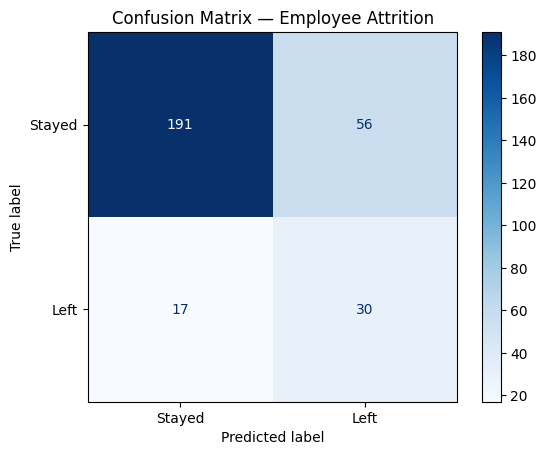

In [72]:
cm = confusion_matrix(
    y_test_cls,
    y_pred_cls,
    labels=[0, 1]
)

cm_display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Stayed", "Left"]
)

cm_display.plot(cmap="Blues")
plt.title("Confusion Matrix — Employee Attrition")
plt.show()